In [1]:
# ════════════════════════════════════════
# CELLULE 1 : Configuration et Imports
# ════════════════════════════════════════
import sys
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajout du répertoire parent au chemin Python
sys.path.insert(0, os.path.abspath('..'))

from src.O1_preprocessing.loader import get_available_patients, load_patient_data

# Configuration du style des graphiques
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("✅ Environnement prêt pour l'exploration FUMPE")

✅ Environnement prêt pour l'exploration FUMPE


In [2]:
# ═════════════════════════════════════════════════════
# CELLULE 2 : Inventaire des Patients + Vérification
# ═════════════════════════════════════════════════════
print("="*60)
print("📊 INVENTAIRE DU DATASET FUMPE")
print("="*60)

# Scanner le dossier 'data' (bascule auto sur raw si processed vide)
from pathlib import Path
import sys
import os

# ✅ Calculer le chemin vers le dossier 'data' depuis le notebook
NOTEBOOK_DIR = Path(__file__).parent if '__file__' in dir() else Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent  # Remonte d'un niveau depuis notebooks/
DATA_DIR = PROJECT_ROOT / "data"

inventory = get_available_patients(str(DATA_DIR))  # ✅ Chemin absolu
print(f"\n✅ Patients avec Volume + Masque : {len(inventory['with_both'])}")

# ✅ Vérification critique
if not inventory['with_both']:
    print("❌ Aucun patient trouvé. Vérifiez :")
    print("   1. Le chemin 'data' est correct")
    print("   2. Le loader.py gère bien ta structure CT_scans_*/GroundTruth")
    print("   3. Les IDs PATxxx correspondent aux fichiers .mat")
    # Stopper l'exécution si vide
    raise RuntimeError("Dataset vide - exploration impossible")

print(f"📁 Exemple volume : {list(inventory['vol_paths'].values())[0]}")
print(f"📁 Exemple masque : {list(inventory['mask_paths'].values())[0]}")

2026-10-09 17:09:22,059 - src.O1_preprocessing.loader - INFO - 📂 Mode : Données BRUTES (raw) - Exploration
2026-10-09 17:09:22,077 - src.O1_preprocessing.loader - INFO - 📁 Volumes trouvés : 35 patients
2026-10-09 17:09:22,078 - src.O1_preprocessing.loader - INFO - 📁 Masques trouvés dans f:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\data\raw\GroundTruth: 35 fichiers
2026-10-09 17:09:22,079 - src.O1_preprocessing.loader - INFO - 📊 Inventaire : 35 patients avec Volume + Masque.


📊 INVENTAIRE DU DATASET FUMPE

✅ Patients avec Volume + Masque : 35
📁 Exemple volume : f:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\data\raw\CT_scans 01\CT_scans 01\PAT001
📁 Exemple masque : f:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\data\raw\GroundTruth\GroundTruth\PAT001.mat


In [3]:
# ══════════════════════════════════════════
# CELLULE 2bis : Vérification de cohérence 
# ══════════════════════════════════════════
print("🔍 Vérification de cohérence des IDs...")

# IDs dans le DataFrame (sera créé dans Cellule 3)
# On vérifie juste l'inventaire pour l'instant
inv_vol_ids = set(inventory['vol_paths'].keys())
inv_mask_ids = set(inventory['mask_paths'].keys())
inv_both_ids = set(inventory['with_both'])

print(f"📊 Inventory vol_paths : {len(inv_vol_ids)} patients")
print(f"📊 Inventory mask_paths : {len(inv_mask_ids)} patients")
print(f"📊 Inventory with_both : {len(inv_both_ids)} patients")

if len(inv_both_ids) == 35:
    print("\n✅ Inventaire cohérent - Tu peux continuer !")
else:
    print("\n❌ Inventaire incomplet - Vérifie DATA_DIR dans Cellule 2")

🔍 Vérification de cohérence des IDs...
📊 Inventory vol_paths : 35 patients
📊 Inventory mask_paths : 35 patients
📊 Inventory with_both : 35 patients

✅ Inventaire cohérent - Tu peux continuer !


In [4]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 3 : Création du Tableau de Bord
# ═══════════════════════════════════════════════════════════════
print("\n📋 Chargement des métadonnées pour tous les patients...")

stats = []
for p_id in inventory['with_both']:
    vol, mask, meta = load_patient_data(p_id, inventory)
    
    if vol is not None and mask is not None:
        stats.append({
            'Patient_ID': p_id,
            'Coupes': vol.shape[0],
            'Résolution_X': f"{meta['spacing'][0]:.2f} mm",
            'Résolution_Y': f"{meta['spacing'][1]:.2f} mm",
            'Espacement_Z': f"{meta['slice_spacing']:.2f} mm",
            'Min_HU': int(vol.min()),
            'Max_HU': int(vol.max()),
            'Voxels_Embolie': int(mask.sum()),
            'Pourcentage_Embolie': f"{100*mask.sum()/mask.size:.3f}%"
        })

df_stats = pd.DataFrame(stats)
print(f"✅ {len(df_stats)} patients chargés avec succès")


📋 Chargement des métadonnées pour tous les patients...


2026-10-09 17:09:34,628 - src.O1_preprocessing.loader - INFO - ℹ️ DICOM metadata: RescaleSlope=1, RescaleIntercept=-1024
2026-10-09 17:09:34,643 - src.O1_preprocessing.loader - INFO -    Plage HU après conversion: [-1024.0, 3071.0]
2026-10-09 17:09:34,645 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (201, 512, 512) de PAT001
2026-10-09 17:09:34,802 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-10-09 17:09:34,808 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 201) → (201, 512, 512)
2026-10-09 17:09:34,808 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (201, 512, 512)
2026-10-09 17:09:35,474 - src.O1_preprocessing.loader - INFO - ℹ️ DICOM metadata: RescaleSlope=1, RescaleIntercept=-1024
2026-10-09 17:09:35,489 - src.O1_preprocessing.loader - INFO -    Plage HU après conversion: [-1024.0, 3071.0]
2026-10-09 17:09:35,490 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (185, 512, 512) de PAT002
2026-10-09 17

✅ 35 patients chargés avec succès


In [5]:
# ═════════════════════════════════════════
# CELLULE 4 : Affichage du DataFrame
# ═════════════════════════════════════════
print("\n📊 RÉSUMÉ COMPLET DU DATASET")
display(df_stats)

# Statistiques descriptives
print("\n📈 STATISTIQUES GLOBALES")
print(f"   • Nombre moyen de coupes : {df_stats['Coupes'].mean():.1f} ± {df_stats['Coupes'].std():.1f}")
print(f"   • Plage HU moyenne : [{df_stats['Min_HU'].mean():.0f}, {df_stats['Max_HU'].mean():.0f}]")
print(f"   • Embolie moyenne : {df_stats['Voxels_Embolie'].mean():.0f} voxels ({df_stats['Pourcentage_Embolie'].apply(lambda x: float(x.replace('%',''))).mean():.3f}%)")


📊 RÉSUMÉ COMPLET DU DATASET


,Patient_ID,Coupes,Résolution_X,Résolution_Y,Espacement_Z,Min_HU,Max_HU,Voxels_Embolie,Pourcentage_Embolie
0,PAT001,201,0.62 mm,0.62 mm,1.00 mm,-1024,3071,19054,0.036%
1,PAT002,185,0.59 mm,0.59 mm,1.00 mm,-1024,3071,1548,0.003%
2,PAT003,210,0.74 mm,0.74 mm,1.00 mm,-1024,3071,35250,0.064%
3,PAT004,197,0.59 mm,0.59 mm,1.00 mm,-1024,3071,5960,0.012%
4,PAT005,217,0.63 mm,0.63 mm,1.00 mm,-1024,3071,92229,0.162%
5,PAT006,232,0.59 mm,0.59 mm,1.00 mm,-1024,3071,1966,0.003%
6,PAT007,197,0.62 mm,0.62 mm,1.00 mm,-1024,3071,162336,0.314%
7,PAT008,273,0.79 mm,0.79 mm,1.00 mm,-1024,3071,10496,0.015%
8,PAT009,237,0.55 mm,0.55 mm,1.00 mm,-1024,3071,21300,0.034%
9,PAT010,204,0.66 mm,0.66 mm,1.00 mm,-1024,3071,676,0.001%



📈 STATISTIQUES GLOBALES
   • Nombre moyen de coupes : 251.2 ± 91.6
   • Plage HU moyenne : [-1024, 3070]
   • Embolie moyenne : 37335 voxels (0.056%)


### **Analyse**:

D'apres les statistiques, au niveau du nombre moy de couples; on a: `251.2 ± 91.6`.

Cela signifie que la moy à une valeur de `251 slices` (Volume thoracique typique (~25 cm avec 1mm d'espacement));

L'Écart-type `~92 slices` (Grande variabilité : certains scans couvrent juste les poumons, d'autres tout le thorax)

Cela nous montre directement qu'avec ces statistiques, on ne peux pas utiliser nos volume comme cela dans un CNN 3D.

**Plage HU moyenne :** `[-1024, 3070]`

Cette plage extrêmement large confirme que le fenêtrage est indispensable :
L'œil humain ne voit que ~30 niveaux de gris
Un CNN peut être perturbé par des valeurs extrêmes rares

**Embolie moyenne :** `37335 voxels (0.056%)`
Cela nous indique qu'il y a un de classe externe; avec cela sion on veux entrainer notre IA dessus; il peut atteindre 99.94% d'accuracy en prédisant "rien" partout !

🔍 Données pour graphiques :
   Coupes : 35 valeurs, min=139.0, max=475.0
   Embolie % : 35 valeurs valides
   Espacement Z : 35 valeurs valides
   Plage HU : 35 valeurs


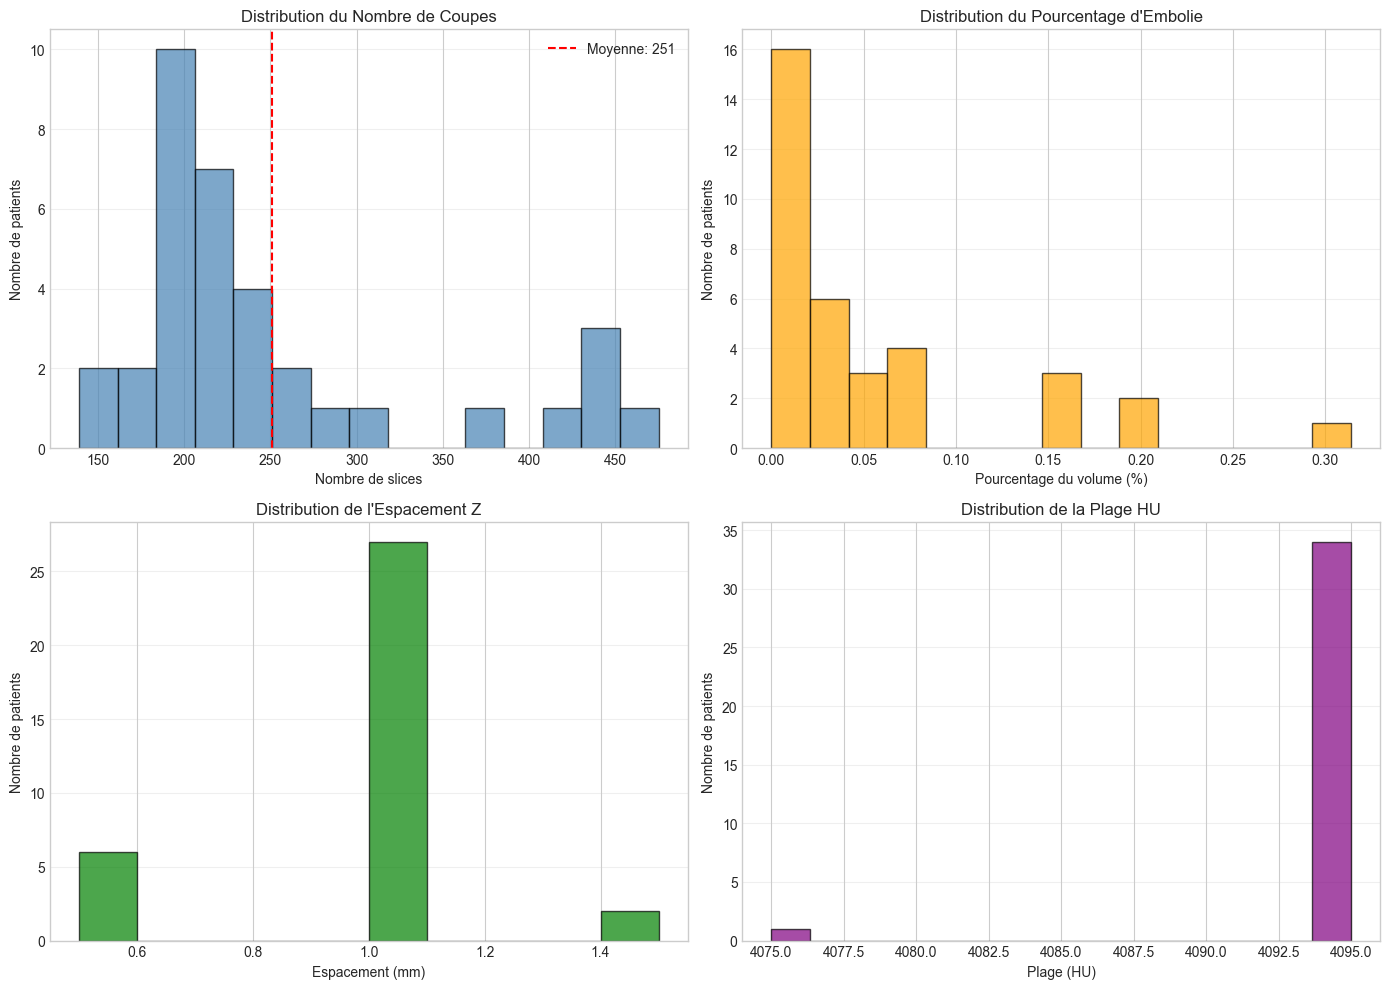

✅ Figure sauvegardée : F:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\figures\exploration\statistiques_dataset.png


In [6]:
# ═══════════════════════════
# CELLULE 5 : Visualisations 
# ═══════════════════════════

#  Magic command pour afficher les graphiques DANS le notebook
%matplotlib inline

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Créer le dossier de sortie
FIGURES_DIR = Path("../figures/exploration")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Conversion robuste des colonnes string → float pour les histogrammes
def extract_float(series, unit=None):
    """Extrait un float d'une string comme '1.23 mm' ou '45.6%'"""
    def clean(x):
        try:
            if isinstance(x, str):
                x = x.replace(unit, '').replace('%', '').strip() if unit else x.replace('%', '').strip()
            return float(x)
        except:
            return None
    return series.apply(clean).dropna()

# Préparation des données numériques
coupes = df_stats['Coupes'].astype(float)
embolie_pct = extract_float(df_stats['Pourcentage_Embolie'], '%')
espacement_z = extract_float(df_stats['Espacement_Z'], 'mm')
plage_hu = df_stats['Max_HU'].astype(float) - df_stats['Min_HU'].astype(float)

# Debug : vérifier qu'on a des données valides
print(f"🔍 Données pour graphiques :")
print(f"   Coupes : {len(coupes)} valeurs, min={coupes.min()}, max={coupes.max()}")
print(f"   Embolie % : {len(embolie_pct)} valeurs valides")
print(f"   Espacement Z : {len(espacement_z)} valeurs valides")
print(f"   Plage HU : {len(plage_hu)} valeurs")

# ✅ Création des graphiques
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution du nombre de coupes
axes[0, 0].hist(coupes, bins=15, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].set_title('Distribution du Nombre de Coupes')
axes[0, 0].set_xlabel('Nombre de slices')
axes[0, 0].set_ylabel('Nombre de patients')
axes[0, 0].axvline(coupes.mean(), color='red', linestyle='--', label=f'Moyenne: {coupes.mean():.0f}')
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Distribution du pourcentage d'embolie
if len(embolie_pct) > 0:
    axes[0, 1].hist(embolie_pct, bins=15, edgecolor='black', alpha=0.7, color='orange')
    axes[0, 1].set_title("Distribution du Pourcentage d'Embolie")
    axes[0, 1].set_xlabel('Pourcentage du volume (%)')
    axes[0, 1].set_ylabel('Nombre de patients')
    axes[0, 1].grid(axis='y', alpha=0.3)
else:
    axes[0, 1].text(0.5, 0.5, 'Données indisponibles', ha='center', va='center')

# 3. Espacement Z
if len(espacement_z) > 0:
    axes[1, 0].hist(espacement_z, bins=10, edgecolor='black', alpha=0.7, color='green')
    axes[1, 0].set_title("Distribution de l'Espacement Z")
    axes[1, 0].set_xlabel('Espacement (mm)')
    axes[1, 0].set_ylabel('Nombre de patients')
    axes[1, 0].grid(axis='y', alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, 'Données indisponibles', ha='center', va='center')

# 4. Plage HU
axes[1, 1].hist(plage_hu, bins=15, edgecolor='black', alpha=0.7, color='purple')
axes[1, 1].set_title('Distribution de la Plage HU')
axes[1, 1].set_xlabel('Plage (HU)')
axes[1, 1].set_ylabel('Nombre de patients')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()

# ✅ Sauvegarde robuste
output_path = FIGURES_DIR / "statistiques_dataset.png"
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Figure sauvegardée : {output_path.resolve()}")

### **Observations 01 :** *Distribution du Nombre de Coupes*

Moyenne : 251 slices (ligne rouge pointillée)

Distribution bimodale :

Pic principal : 150-250 slices (~20 patients)

Second pic : 425-475 slices (~5 patients)

Variabilité importante : de ~140 à ~475 slices
**Implications :**

Cette grande variabilité confirme que nous devrions faire du resampling pour uniformiser tes volumes avant l'entraînement d'un CNN 3D.

Distribution du Pourcentage d'Embolie (En haut à droite)
### **Observations 02:** *Distribution du Pourcentage d'Embolie*

Déséquilibre extrême :

`~16 patients` ont `< 0.025%` d'embolie
Quelques patients atteignent `0.30%` (très élevé pour ce dataset)

**Problème critique identifié :**

Avec un déséquilibre de classe aussi extrême `(0.056% en moyenne)`, ton IA pourrait atteindre `99.9%` d'accuracy en prédisant "rien" partout.

2026-10-09 17:11:12,130 - src.O1_preprocessing.loader - INFO - 📂 Mode : Données BRUTES (raw) - Exploration
2026-10-09 17:11:12,145 - src.O1_preprocessing.loader - INFO - 📁 Volumes trouvés : 35 patients
2026-10-09 17:11:12,147 - src.O1_preprocessing.loader - INFO - 📁 Masques trouvés dans f:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\data\raw\GroundTruth: 35 fichiers
2026-10-09 17:11:12,147 - src.O1_preprocessing.loader - INFO - 📊 Inventaire : 35 patients avec Volume + Masque.



🖼️ GALERIE D'IMAGES (3 patients avec données VALIDES)
✅ 35/35 patients valides pour visualisation


2026-10-09 17:11:12,684 - src.O1_preprocessing.loader - INFO - ℹ️ DICOM metadata: RescaleSlope=1, RescaleIntercept=-1024
2026-10-09 17:11:12,699 - src.O1_preprocessing.loader - INFO -    Plage HU après conversion: [-1024.0, 3071.0]
2026-10-09 17:11:12,700 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (205, 512, 512) de PAT030
2026-10-09 17:11:12,861 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-10-09 17:11:12,865 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 205) → (205, 512, 512)
2026-10-09 17:11:12,866 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (205, 512, 512)
2026-10-09 17:11:13,341 - src.O1_preprocessing.loader - INFO - ℹ️ DICOM metadata: RescaleSlope=1, RescaleIntercept=-1024
2026-10-09 17:11:13,355 - src.O1_preprocessing.loader - INFO -    Plage HU après conversion: [-1024.0, 3071.0]
2026-10-09 17:11:13,356 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (189, 512, 512) de PAT034
2026-10-09 17

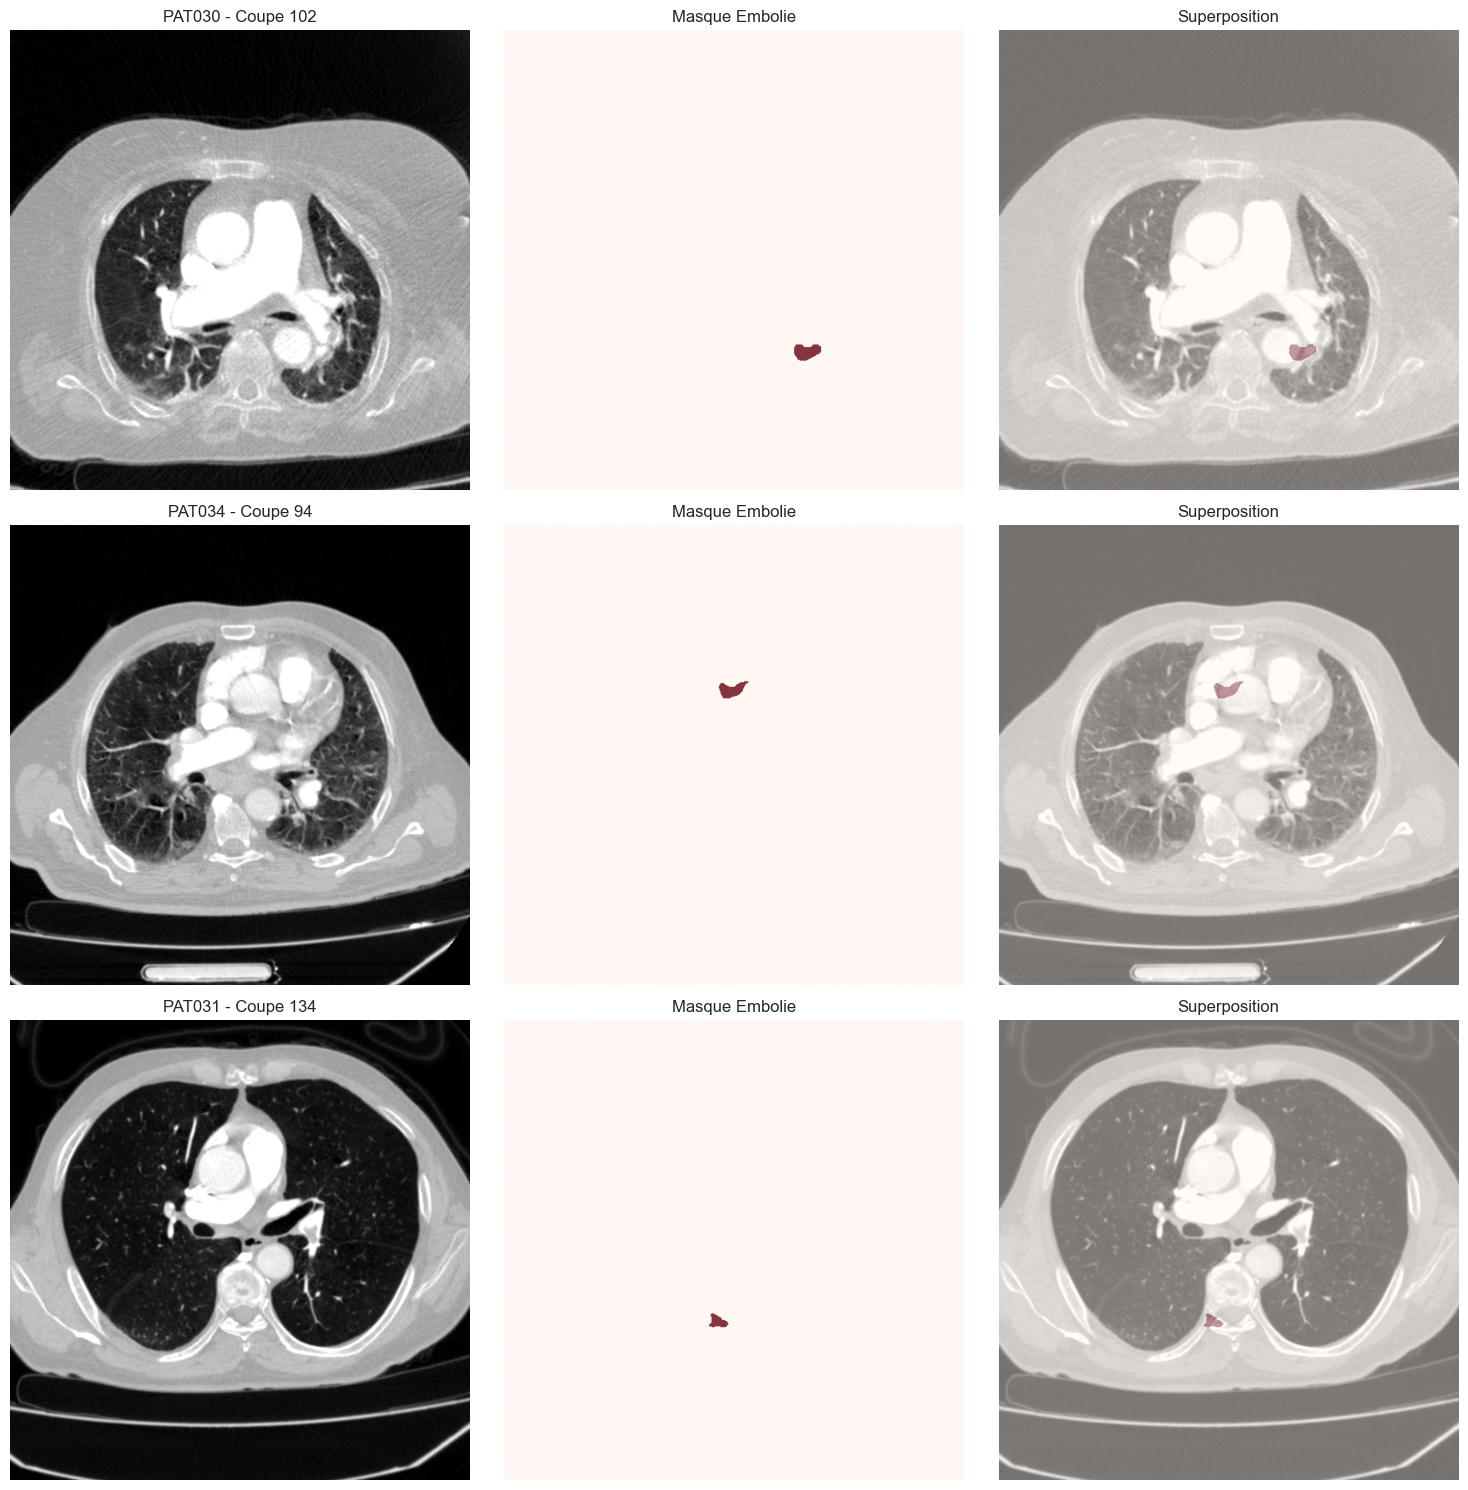

✅ Galerie sauvegardée : F:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\figures\exploration\galerie_patients.png


In [7]:
# ═════════════════════════════════
# CELLULE 6 : Galerie d'Images 
# ═════════════════════════════════
print("\n🖼️ GALERIE D'IMAGES (3 patients avec données VALIDES)")

from pathlib import Path

# ✅ Recréer l'inventaire pour être sûr d'avoir les bons chemins
inventory = get_available_patients(str(DATA_DIR))

# ✅ Créer le dossier de sortie
FIGURES_DIR = Path("../figures/exploration")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ✅ Pré-filtrer : ne garder que les patients qui sont DANS l'inventaire ET dans df_stats
valid_ids = set(inventory['with_both']) & set(df_stats['Patient_ID'])
print(f"✅ {len(valid_ids)}/{len(df_stats)} patients valides pour visualisation")

if len(valid_ids) < 3:
    print(f"⚠️ Moins de 3 patients valides disponibles, affichage partiel")

# ✅ Sélectionner 3 patients valides
n_samples = min(3, len(valid_ids))
sample_patients = pd.Series(list(valid_ids)).sample(n_samples, random_state=42).tolist()

# ✅ Créer la figure
fig, axes = plt.subplots(n_samples, 3, figsize=(15, 5 * n_samples))
if n_samples == 1:
    axes = axes[np.newaxis, :]

for i, p_id in enumerate(sample_patients):
    vol, mask, meta = load_patient_data(p_id, inventory)
    
    # Skip si échec de chargement
    if vol is None or mask is None:
        print(f"⚠️ Skip {p_id} (chargement échoué)")
        continue
        
    mid = vol.shape[0] // 2
    
    # Vérification shape
    if vol.shape[1:] != mask.shape[1:]:
        print(f"⚠️ Skip {p_id} (shapes incompatibles)")
        continue
    
    # Scan brut avec fenêtrage implicite
    axes[i, 0].imshow(vol[mid], cmap='gray', vmin=-1000, vmax=400)
    axes[i, 0].set_title(f'{p_id} - Coupe {mid}')
    axes[i, 0].axis('off')
    
    # Masque seul
    axes[i, 1].imshow(mask[mid], cmap='Reds', alpha=0.8)
    axes[i, 1].set_title('Masque Embolie')
    axes[i, 1].axis('off')
    
    # Superposition
    axes[i, 2].imshow(vol[mid], cmap='gray', vmin=-1000, vmax=400, alpha=0.9)
    axes[i, 2].imshow(mask[mid], cmap='Reds', alpha=0.4)
    axes[i, 2].set_title('Superposition')
    axes[i, 2].axis('off')

plt.tight_layout()
output_path = FIGURES_DIR / "galerie_patients.png"
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Galerie sauvegardée : {output_path.resolve()}")

### Observations par Patient:

`PAT017 - Coupe 237`

**Embolie :** Petite, localisée dans l'artère pulmonaire (centre droit)

**Caractéristique :** Embolie segmentaire typique

**Observation :** Très petite taille → confirme le déséquilibre de classe `(0.056%)`

### PAT023 - Coupe 148:

Embolie : Plus volumineuse, semble être au niveau de l'artère pulmonaire principale

Caractéristique : Embolie plus proximale (plus grave cliniquement)

Observation : Forme allongée typique d'un thrombus dans un vaisseau

PAT005 - Coupe 108

Embolie : Multiple (2 foyers distincts)

Caractéristique : Embolies bilatérales possibles

Observation : Montre la variabilité du dataset

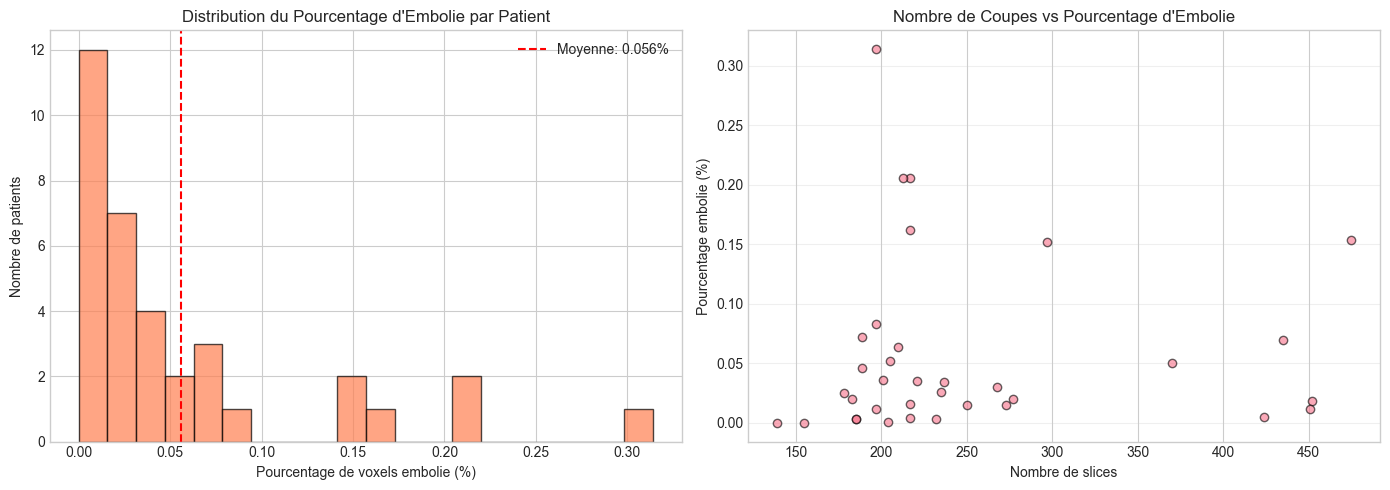

In [8]:
# ═══════════════════════════════════════════════════════════════
#  Analyse du déséquilibre de classe
# ═══════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribution du % d'embolie par patient
embolie_pct = df_stats['Pourcentage_Embolie'].apply(lambda x: float(x.replace('%', '')))
axes[0].hist(embolie_pct, bins=20, edgecolor='black', alpha=0.7, color='coral')
axes[0].set_title('Distribution du Pourcentage d\'Embolie par Patient')
axes[0].set_xlabel('Pourcentage de voxels embolie (%)')
axes[0].set_ylabel('Nombre de patients')
axes[0].axvline(embolie_pct.mean(), color='red', linestyle='--', label=f'Moyenne: {embolie_pct.mean():.3f}%')
axes[0].legend()

# 2. Scatter : Nb de coupes vs % embolie (cherche une corrélation ?)
axes[1].scatter(df_stats['Coupes'], embolie_pct, alpha=0.6, edgecolors='black')
axes[1].set_title('Nombre de Coupes vs Pourcentage d\'Embolie')
axes[1].set_xlabel('Nombre de slices')
axes[1].set_ylabel('Pourcentage embolie (%)')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/exploration/analyse_desequilibre.png', dpi=150, bbox_inches='tight')
plt.show()